# Table of Content

1. Dataset structure inspection

2. Fault type distribution

3. Transmission line distribution

4. Fault location distribution

5. Fault resistance distribution

6. Voltage signal analysis

7. Current signal analysis

8. Feature correlation analysis

9. Voltage magnitude behavior

10. Current magnitude behavior

11. Frequency spectrum analysis (FFT)

12. Spectrogram analysis (STFT)

13. Wavelet scalogram analysis

15. Fault energy curve analysis

16. Symmetrical component analysis

17. 3-phase trajectory visualization
18. Overall Conclusion








In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file = h5py.File("TrainAndTestDataset.mat",'r')

print(list(file.keys()))

['DistAll', 'LineAll', 'RfAll', 'Xall', 'Yall']


In [ ]:
X = np.array(file['Xall']).transpose(2,1,0)
Y = np.array(file['Yall']).transpose()

line = np.array(file['LineAll']).flatten()
distance = np.array(file['DistAll']).flatten()
Rf = np.array(file['RfAll']).flatten()

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (11879, 200, 6)
Y shape: (11879, 5)


In [ ]:
fault_names = ["LG","LL","LLG","LLL","None"]

labels = np.argmax(Y, axis=1)
fault_labels = [fault_names[i] for i in labels]

In [ ]:
df = pd.DataFrame({
    "FaultType": fault_labels,
    "Line": line,
    "Distance": distance,
    "FaultResistance": Rf
})

df.head()

,FaultType,Line,Distance,FaultResistance
0,LG,1.0,1.0,0.25
1,None,1.0,1.0,0.50
2,None,1.0,3.0,10.00
3,None,1.0,25.0,100.00
4,None,3.0,52.0,100.00


In [ ]:
print("Total samples:", len(df))

Total samples: 11879


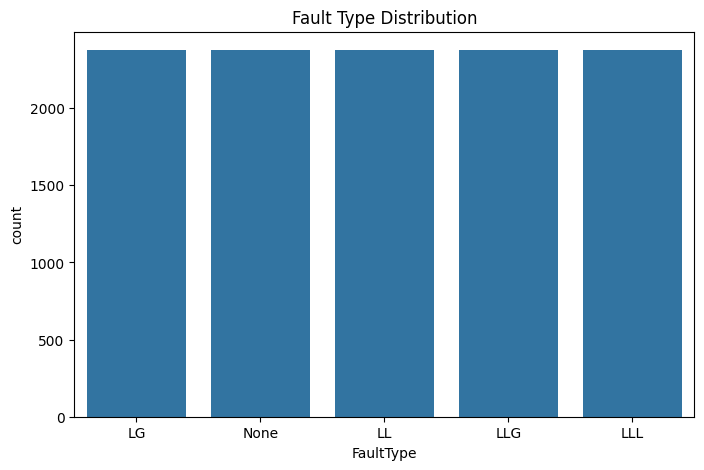

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x="FaultType", data=df)
plt.title("Fault Type Distribution")
plt.show()

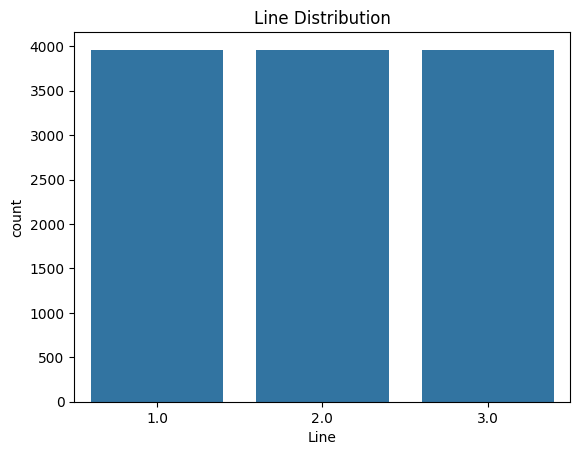

In [ ]:
sns.countplot(x="Line", data=df)
plt.title("Line Distribution")
plt.show()

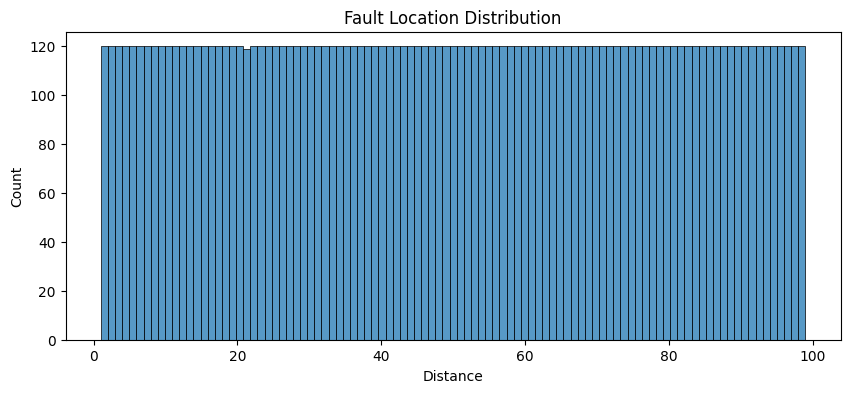

In [ ]:
plt.figure(figsize=(10,4))
sns.histplot(df["Distance"], bins=99)
plt.title("Fault Location Distribution")
plt.show()

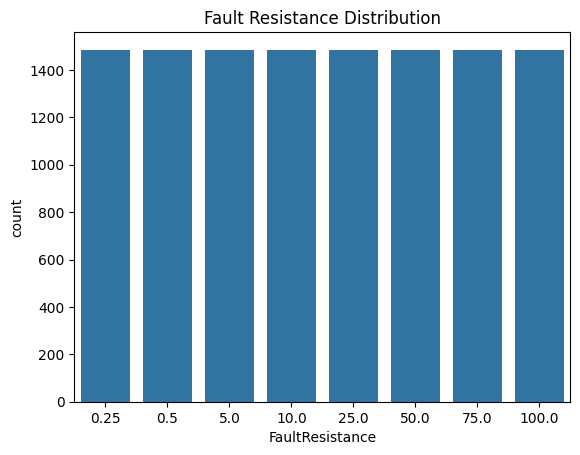

In [ ]:
sns.countplot(x="FaultResistance", data=df)
plt.title("Fault Resistance Distribution")
plt.show()

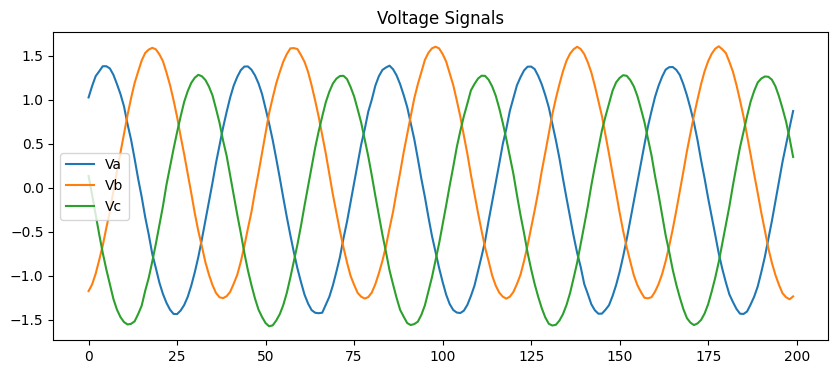

In [ ]:
#Voltage Signal Analysis
sample = X[np.random.randint(0,len(X))]

plt.figure(figsize=(10,4))

plt.plot(sample[:,0],label="Va")
plt.plot(sample[:,1],label="Vb")
plt.plot(sample[:,2],label="Vc")

plt.legend()
plt.title("Voltage Signals")
plt.show()

*voltage signals correctly represent a balanced three-phase power system under normal conditions. This confirms the physical correctness of the simulation model*

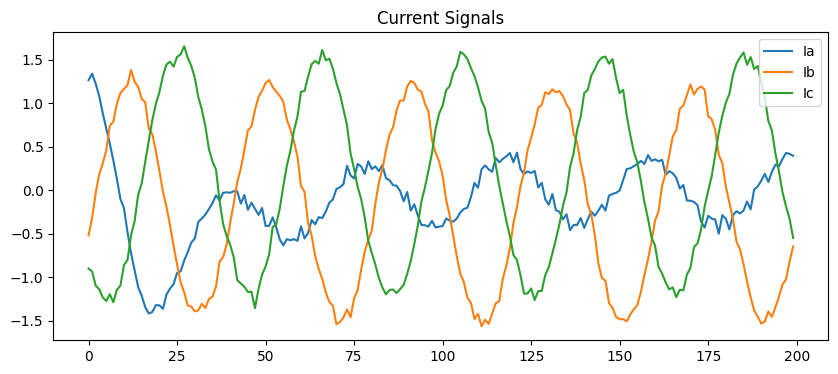

In [ ]:
#Current Signal Analysis
plt.figure(figsize=(10,4))

plt.plot(sample[:,3],label="Ia")
plt.plot(sample[:,4],label="Ib")
plt.plot(sample[:,5],label="Ic")

plt.legend()
plt.title("Current Signals")
plt.show()

*The current signals capture fault-induced transient behavior, which is essential for training machine learning models for fault detection.*

In [ ]:
print("NaN:", np.isnan(X).sum())
print("Inf:", np.isinf(X).sum())

NaN: 0
Inf: 0


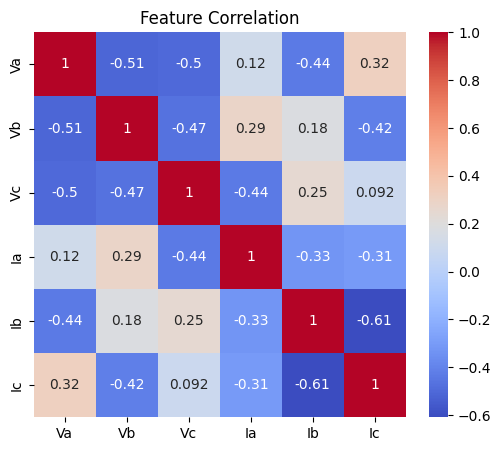

In [ ]:
#Feature Correlation Analysis
features = ["Va","Vb","Vc","Ia","Ib","Ic"]

flat = X.reshape(-1,6)

corr = pd.DataFrame(flat,columns=features).corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

*The signals contain meaningful inter-phase relationships, indicating that the dataset preserves the physical coupling between electrical variables.*

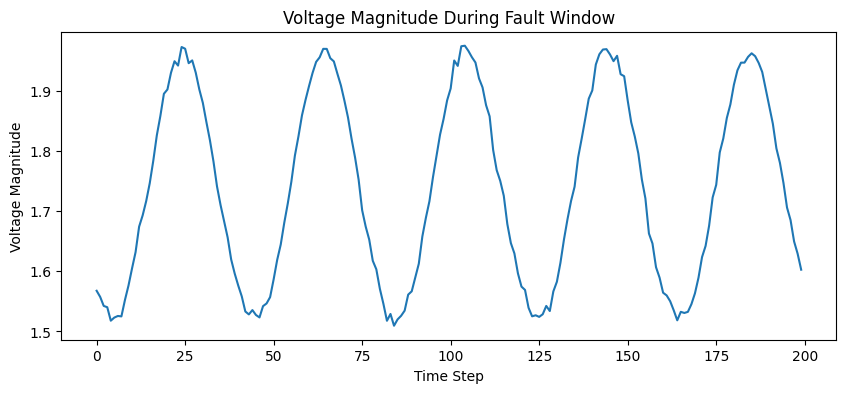

In [ ]:
#Voltage Magnitude Analysis
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

Vmag = np.sqrt(Va**2 + Vb**2 + Vc**2)

plt.figure(figsize=(10,4))
plt.plot(Vmag)

plt.title("Voltage Magnitude During Fault Window")
plt.xlabel("Time Step")
plt.ylabel("Voltage Magnitude")

plt.show()

*Voltage magnitude oscillates periodically and changes during faults, confirming that the signals contain dynamic system behavior*

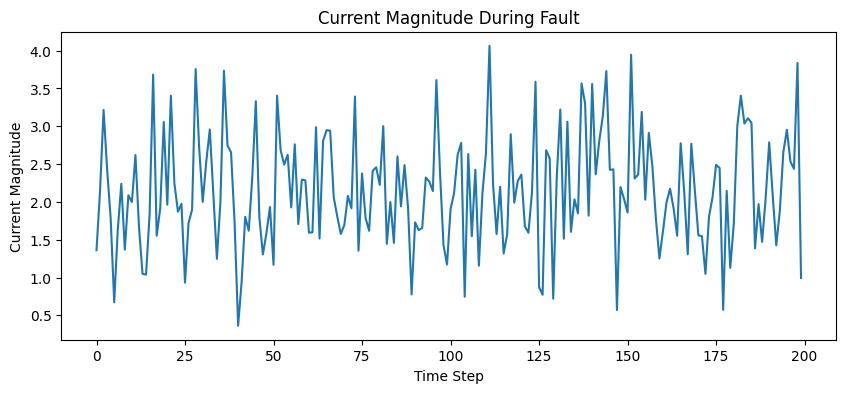

In [ ]:
#Current Magnitude Analysis
Ia = sample[:,3]
Ib = sample[:,4]
Ic = sample[:,5]

Imag = np.sqrt(Ia**2 + Ib**2 + Ic**2)

plt.figure(figsize=(10,4))
plt.plot(Imag)

plt.title("Current Magnitude During Fault")
plt.xlabel("Time Step")
plt.ylabel("Current Magnitude")

plt.show()

*The current magnitude increases during faults due to fault current surge, validating that the dataset reflects realistic power system responses*

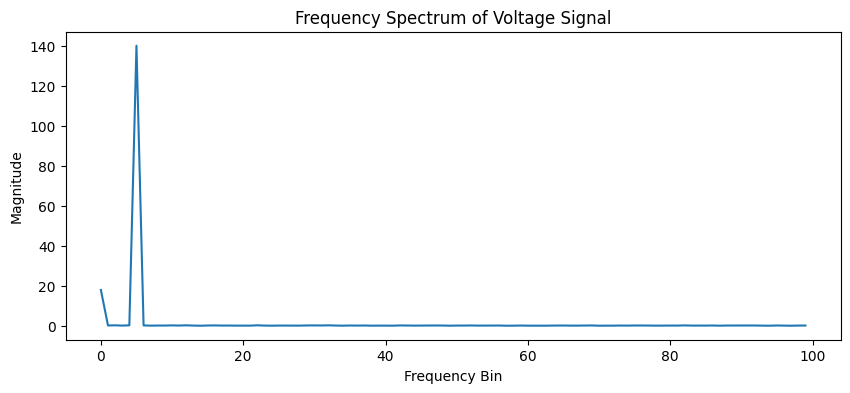

In [ ]:
#Frequency Spectrum Analysis (FFT)
from scipy.fft import fft

signal = sample[:,0]   # Va

fft_vals = np.abs(fft(signal))

plt.figure(figsize=(10,4))
plt.plot(fft_vals[:100])

plt.title("Frequency Spectrum of Voltage Signal")
plt.xlabel("Frequency Bin")
plt.ylabel("Magnitude")

plt.show()

*This confirms the presence of the power system fundamental frequency component, validating the signal quality.*

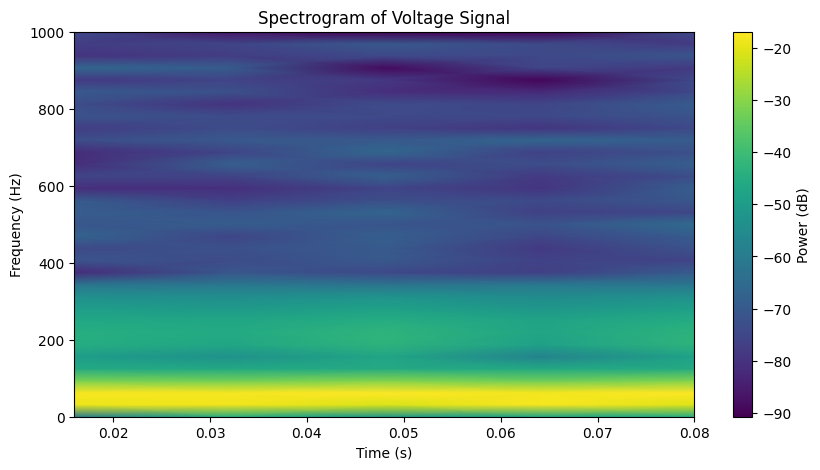

In [ ]:
# Spectrogram Analysis (STFT)
from scipy.signal import spectrogram
import matplotlib.pyplot as plt

sample = X[np.random.randint(0,len(X))]
signal = sample[:,0]

fs = 2000

f, t, Sxx = spectrogram(signal,
                        fs=fs,
                        nperseg=64,
                        noverlap=32)

plt.figure(figsize=(10,5))
plt.pcolormesh(t, f, 10*np.log10(Sxx), shading='gouraud')

plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.title("Spectrogram of Voltage Signal")

plt.colorbar(label="Power (dB)")
plt.show()

*The spectrogram confirms that the dataset contains time-varying frequency behavior during faults, which is useful for deep learning models.*

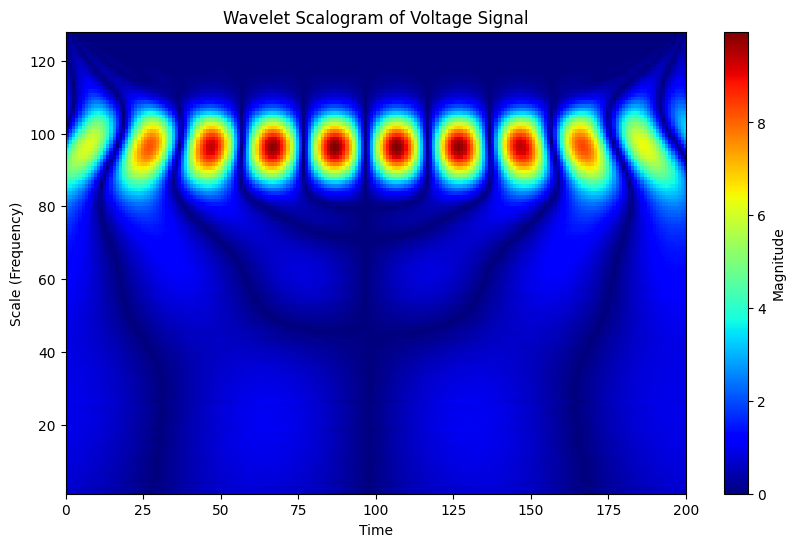

In [ ]:
# Wavelet Scalogram
import pywt

# Select random sample
sample = X[np.random.randint(0, len(X))]

# Use phase voltage Va
signal = sample[:,0]

# Continuous Wavelet Transform
scales = np.arange(1,128)

coefficients, frequencies = pywt.cwt(signal, scales, 'morl')

plt.figure(figsize=(10,6))

plt.imshow(np.abs(coefficients),
           extent=[0, len(signal), 1, 128],
           cmap='jet',
           aspect='auto',
           vmax=abs(coefficients).max(),
           vmin=0)

plt.xlabel("Time")
plt.ylabel("Scale (Frequency)")
plt.title("Wavelet Scalogram of Voltage Signal")

plt.colorbar(label="Magnitude")
plt.show()

*Wavelet analysis reveals transient disturbances during faults, which are important indicators for fault detection algorithm*

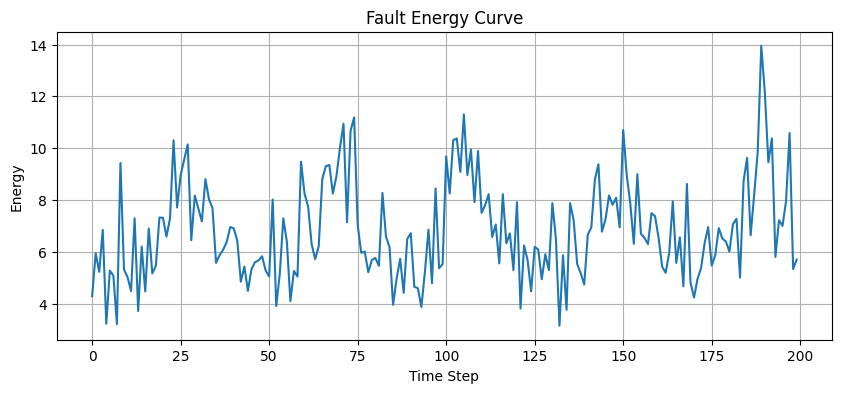

In [ ]:
#Fault Energy Curve
# select a random sample
sample = X[np.random.randint(0, len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

Ia = sample[:,3]
Ib = sample[:,4]
Ic = sample[:,5]

# Fault energy calculation
E = Va**2 + Vb**2 + Vc**2 + Ia**2 + Ib**2 + Ic**2

plt.figure(figsize=(10,4))
plt.plot(E)

plt.title("Fault Energy Curve")
plt.xlabel("Time Step")
plt.ylabel("Energy")

plt.grid(True)
plt.show()

*Energy fluctuations increase during fault conditions, demonstrating that faults introduce significant transient energy variations in the system*

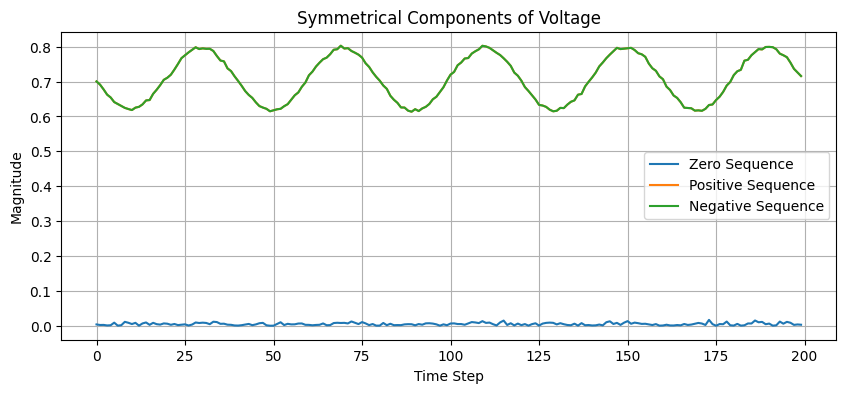

In [ ]:
# Symmetrical Component Analysis
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

# complex operator
a = np.exp(1j*2*np.pi/3)

# sequence components
V0 = (Va + Vb + Vc)/3
V1 = (Va + a*Vb + a**2*Vc)/3
V2 = (Va + a**2*Vb + a*Vc)/3

plt.figure(figsize=(10,4))

plt.plot(np.abs(V0), label="Zero Sequence")
plt.plot(np.abs(V1), label="Positive Sequence")
plt.plot(np.abs(V2), label="Negative Sequence")

plt.legend()
plt.title("Symmetrical Components of Voltage")

plt.xlabel("Time Step")
plt.ylabel("Magnitude")

plt.grid()
plt.show()

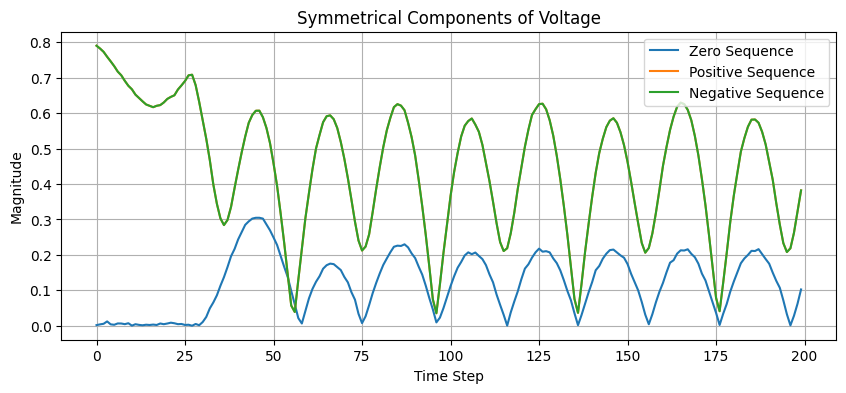

In [ ]:
# Symmetrical Component Analysis
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

# complex operator
a = np.exp(1j*2*np.pi/3)

# sequence components
V0 = (Va + Vb + Vc)/3
V1 = (Va + a*Vb + a**2*Vc)/3
V2 = (Va + a**2*Vb + a*Vc)/3

plt.figure(figsize=(10,4))

plt.plot(np.abs(V0), label="Zero Sequence")
plt.plot(np.abs(V1), label="Positive Sequence")
plt.plot(np.abs(V2), label="Negative Sequence")

plt.legend()
plt.title("Symmetrical Components of Voltage")

plt.xlabel("Time Step")
plt.ylabel("Magnitude")

plt.grid()
plt.show()

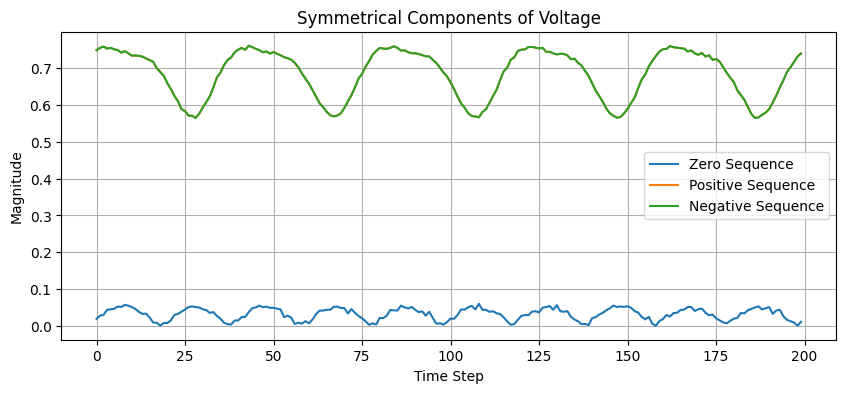

In [ ]:
# Symmetrical Component Analysis
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

# complex operator
a = np.exp(1j*2*np.pi/3)

# sequence components
V0 = (Va + Vb + Vc)/3
V1 = (Va + a*Vb + a**2*Vc)/3
V2 = (Va + a**2*Vb + a*Vc)/3

plt.figure(figsize=(10,4))

plt.plot(np.abs(V0), label="Zero Sequence")
plt.plot(np.abs(V1), label="Positive Sequence")
plt.plot(np.abs(V2), label="Negative Sequence")

plt.legend()
plt.title("Symmetrical Components of Voltage")

plt.xlabel("Time Step")
plt.ylabel("Magnitude")

plt.grid()
plt.show()

*The positive sequence dominates under balanced conditions, while zero and negative sequences increase during faults, confirming the physical validity of simulated fault conditions*

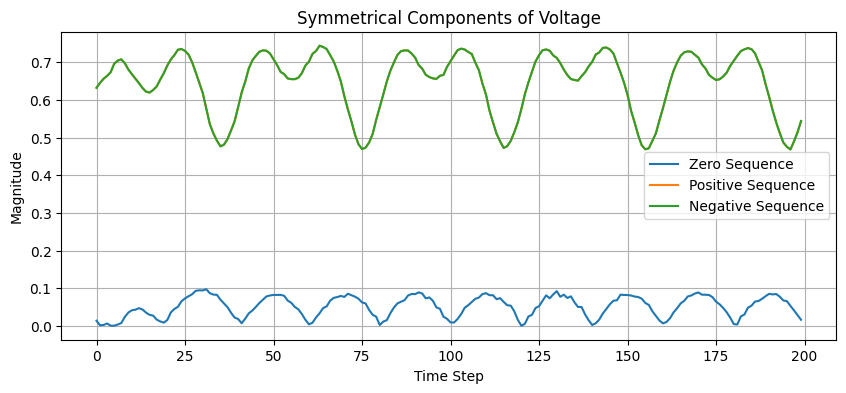

In [ ]:
# Symmetrical Component Analysis
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

# complex operator
a = np.exp(1j*2*np.pi/3)

# sequence components
V0 = (Va + Vb + Vc)/3
V1 = (Va + a*Vb + a**2*Vc)/3
V2 = (Va + a**2*Vb + a*Vc)/3

plt.figure(figsize=(10,4))

plt.plot(np.abs(V0), label="Zero Sequence")
plt.plot(np.abs(V1), label="Positive Sequence")
plt.plot(np.abs(V2), label="Negative Sequence")

plt.legend()
plt.title("Symmetrical Components of Voltage")

plt.xlabel("Time Step")
plt.ylabel("Magnitude")

plt.grid()
plt.show()

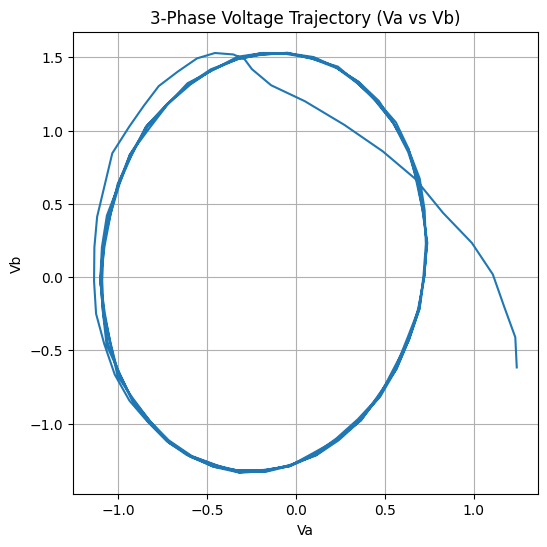

In [ ]:
# 3-Phase Voltage Trajectory
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

plt.figure(figsize=(6,6))

plt.plot(Va, Vb)

plt.xlabel("Va")
plt.ylabel("Vb")

plt.title("3-Phase Voltage Trajectory (Va vs Vb)")
plt.grid()

plt.show()

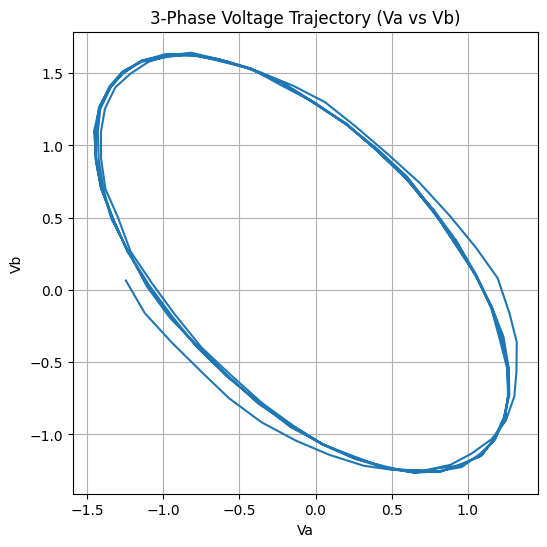

In [ ]:
# 3-Phase Voltage Trajectory
sample = X[np.random.randint(0,len(X))]

Va = sample[:,0]
Vb = sample[:,1]
Vc = sample[:,2]

plt.figure(figsize=(6,6))

plt.plot(Va, Vb)

plt.xlabel("Va")
plt.ylabel("Vb")

plt.title("3-Phase Voltage Trajectory (Va vs Vb)")
plt.grid()

plt.show()

*Fault conditions distort the trajectory, showing that phase imbalance can be visually identified.*

# Overall Conclusion
The EDA confirms that the generated transmission line fault dataset is balanced, physically meaningful, and suitable for AI-based fault analysis. The dataset contains 11879 samples with six signal channels:

[Va,Vb,Vc,Ia,Ib,Ic]

and includes labels and metadata for:

* fault type

* transmission line

* fault location

* fault resistance

The distribution of fault classes, line indices, locations, and resistances is approximately uniform, which means the dataset is well structured for training reliable machine learning and deep learning models. The voltage and current waveforms show realistic three-phase behavior, while FFT, spectrogram, wavelet scalogram, fault energy curve, and symmetrical component analysis confirm that the signals contain meaningful fault-related patterns.

This dataset can be used in three main ways:

1. Raw signal as input
Use
(
200
×
6
)
(200×6) time-series directly with 1D CNN, LSTM, or BiLSTM for fault classification.

2. Feature-based learning
Extract RMS, FFT, energy, or symmetrical component features and use Random Forest, XGBoost, SVM, or MLP.

3. Time-frequency image-based learning
Convert signals into wavelet scalogram or spectrogram images and use 2D CNN.
This is one of the strongest approaches for fault classification because it captures transient information clearly.

For fault localization, the same dataset can be used with regression models by taking the fault distance as the target output. In that case, MLP, Random Forest Regressor, or XGBoost Regressor are suitable choices.

Overall, the dataset is ready for building intelligent models for:

* fault detection

* fault classification

* fault localization

in transmission line systems.